# KA SS 26 · Challenge 2 — **Stage 5 (Google Colab): ConvNeXt-UNet + watershed**

A deliberately **different kind of model** from Stage 3 and Stage 4, not a reconfiguration of them.

|  | Stage 3 / Stage 4 | Stage 5 |
|---|---|---|
| Paradigm | region proposals + RoI heads + NMS | dense per-pixel prediction + marker-controlled watershed |
| Instance cap | hard `detections_per_img` limit | **none** — cost is flat in cell count |
| Backbone | ResNet-50 FPN | ConvNeXt-Tiny |
| Pretraining | COCO detector | **ImageNet-21k → 1k**, classification only |
| Fails on | very dense images (capacity-bound) | large, smoothly-touching cells |

**Why this model.** The official metric gates a match at Dice ≥ 0.50, i.e. IoU ≥ 1/3. That is lenient on
boundaries, so almost all of the score comes from *separating and counting* instances rather than tracing
them precisely — which is what watershed on eroded seed markers is good at. Stage 2 predicted at most 476
masks on a test image while the dataset reaches 782 instances, so the proposal-based models are
capacity-bound on exactly the images this model handles best.

**Overlapping masks.** Watershed produces a hard partition and cannot represent overlaps. That is
acceptable here: Stage 2's own sweep selected `allow_overlap = False`, and the overlapping share of
foreground is far too small to drag a good match below Dice 0.50.

**Pretrained weights.** `convnext_tiny.fb_in22k_ft_in1k` — generic image classification only. No
cell-specific, microscopy, medical, LIVECell or Cellpose weights are used anywhere in this notebook.

**Expected result: roughly 0.35–0.48 on its own, probably below Stage 3.** Its value is decorrelated
errors and uncapped dense-image recall, so judge it on those rather than on beating Stage 3.

Target runtime on one Colab T4: **about 75–100 minutes** end to end, protected by a wall-clock guard.

---
### Run order
1. Runtime → Change runtime type → **T4 GPU**.
2. Run cell 1 (GPU + dependencies).
3. Fill in the data section in cell 3, then run everything (Runtime → Run all).


## 1 · GPU check, dependencies, imports

In [1]:
import subprocess, sys, os

print(subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,driver_version",
                      "--format=csv,noheader"], capture_output=True, text=True).stdout.strip()
      or "NO GPU DETECTED -> Runtime > Change runtime type > T4 GPU")

def pip_install(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)

try:
    import timm
except ImportError:
    pip_install("timm")
    import timm

import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import math, time, json, random, gc, shutil, pickle, warnings
from pathlib import Path
from collections import defaultdict, Counter
from PIL import Image
from scipy import ndimage as ndi
from scipy.sparse import csr_matrix, csgraph
from skimage.segmentation import watershed
import cv2
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
T_START = time.time()

def elapsed_seconds(): return time.time() - T_START
def format_duration(s): return f"{int(s // 3600)}h {int((s % 3600) // 60):02d}m"

def seed_everything(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True

print("torch  :", torch.__version__)
print("timm   :", timm.__version__)
print("opencv :", cv2.__version__)
print("device :", DEVICE)
assert DEVICE.type == "cuda", "Enable the T4 GPU runtime before continuing."


Tesla T4, 15360 MiB, 580.82.07
torch  : 2.11.0+cu128
timm   : 1.0.28
opencv : 4.13.0
device : cuda


## 2 · Configuration

In [2]:
class CFG:
    SEED = 2026
    SMOKE_TEST = False           # True -> 2 epochs on a handful of images, ~4 minutes

    # ---- wall clock (Colab free tier disconnects; keep this honest) ----
    TOTAL_BUDGET_SEC = 1.9 * 3600
    RESERVE_SEC = 16 * 60        # kept for the sweep, test inference and submission

    # ---- data ----
    IMG_H, IMG_W = 520, 704
    PAD_H, PAD_W = 544, 704      # padded to a multiple of 32 for the encoder
    CROP_H, CROP_W = 448, 576    # random training crop

    # ---- validation ----
    GROUP_SPLIT = True           # never split near-duplicate images across train/val
    DUP_CORR_THR = 0.72
    N_FOLDS = 5
    FOLD = 0                     # same fold as Stage 3/4 -> scores are comparable
    CLUSTER_K_RANGE = (2, 3, 4, 5)

    # ---- model ----
    ENCODER = "convnext_tiny.fb_in22k_ft_in1k"
    ENCODER_FALLBACKS = ("convnext_tiny", "resnet34")
    DECODER_CHANNELS = (256, 128, 64, 32)
    OUT_CHANNELS = 2             # 0 = cell foreground, 1 = eroded seed

    # ---- targets ----
    SEED_EROSION_FRAC = 0.45     # seed = distance transform > 45% of the instance's max
    BORDER_DILATION = 2          # px; pixels shared by >=2 dilated instances are boundaries
    BORDER_WEIGHT = 4.0          # loss weight multiplier on those boundary pixels

    # ---- optimisation (tuned for an ImageNet encoder + random decoder) ----
    EPOCHS = 70
    BATCH_SIZE = 8
    ACCUM_STEPS = 1
    LR = 3e-4                    # decoder / head
    ENCODER_LR_MULT = 0.25       # pretrained encoder moves slower
    WEIGHT_DECAY = 1e-4
    WARMUP_STEPS = 150
    GRAD_CLIP = 5.0
    FREEZE_ENCODER_EPOCHS = 2    # decoder is random; let it settle before touching the encoder
    AMP = True
    NUM_WORKERS = 2
    USE_EMA = True
    EMA_DECAY = 0.999

    # ---- augmentation ----
    AUG_HFLIP = 0.5
    AUG_VFLIP = 0.5
    AUG_ROT90 = 0.5
    AUG_SCALE = 0.5              # probability of scale jitter
    AUG_SCALE_RANGE = (0.85, 1.20)
    AUG_BRIGHTNESS_CONTRAST = 0.5
    AUG_GAMMA = 0.3
    AUG_NOISE = 0.2

    # ---- evaluation / decoding ----
    EVAL_START_EPOCH = 6
    EVAL_EVERY = 3
    EVAL_T_CELL = 0.50
    EVAL_T_SEED = 0.50
    DICE_MATCH_THR = 0.50
    TTA_FLIPS = True             # 4x dihedral averaging at inference; safe for dense prediction

    # ---- post-processing sweep ----
    SWEEP_T_CELL = (0.35, 0.45, 0.55, 0.65)
    SWEEP_T_SEED = (0.35, 0.45, 0.55, 0.65)
    SWEEP_MIN_AREA_Q = (0.00, 0.01, 0.03, 0.06, 0.10)
    SWEEP_SCORE_THR = tuple(np.round(np.arange(0.30, 0.96, 0.02), 2))
    ROBUST_THRESHOLD = True
    ROBUST_TOL = 0.004

    # ---- submission ----
    SUB_INDEX_COL = "idx"
    RUN_TAG = "stage5_convnext_unet_ws"
    PROBE_DELTAS = (-0.10, 0.10)
    SAVE_CACHES = True

if CFG.SMOKE_TEST:
    CFG.EPOCHS = 2
    CFG.EVAL_START_EPOCH = 1
    CFG.EVAL_EVERY = 1
    CFG.FREEZE_ENCODER_EPOCHS = 0
    CFG.SWEEP_T_CELL = (0.45, 0.55)
    CFG.SWEEP_T_SEED = (0.45, 0.55)
    CFG.SWEEP_MIN_AREA_Q = (0.00, 0.05)

seed_everything(CFG.SEED)
STATS = {}
NPIX = CFG.IMG_H * CFG.IMG_W
print("epochs:", CFG.EPOCHS, "| budget:", format_duration(CFG.TOTAL_BUDGET_SEC),
      "| encoder:", CFG.ENCODER)


epochs: 70 | budget: 1h 54m | encoder: convnext_tiny.fb_in22k_ft_in1k


## 3 · Data access — Kaggle API

This notebook now uses the Kaggle API directly instead of a manually uploaded ZIP.

Before running:

1. Join the competition and accept its rules on Kaggle.
2. Download `kaggle.json` from Kaggle **Settings → API → Create Legacy API Key**.
3. Upload it to Google Drive at:
   `/content/drive/MyDrive/ka_ss26/kaggle.json`

The competition files will be downloaded into `/content/data`, while checkpoints and artifacts remain in Google Drive.


In [3]:
from pathlib import Path
from google.colab import drive

# Mount Google Drive first so kaggle.json is available.
drive.mount('/content/drive', force_remount=False)

KAGGLE_JSON = Path("/content/kaggle.json")
KAGGLE_COMPETITION = "ka-ss-26-challenge-2"
DRIVE_WORKDIR = Path("/content/drive/MyDrive/ka_ss26/stage5")

print("kaggle.json exists:", KAGGLE_JSON.is_file())
assert KAGGLE_JSON.is_file()

print('kaggle.json exists:', KAGGLE_JSON.is_file())
print('competition slug  :', KAGGLE_COMPETITION)
print('work directory    :', DRIVE_WORKDIR)

assert KAGGLE_JSON.is_file(), (
    f'Missing Kaggle credentials: {KAGGLE_JSON}\n'
    'Upload kaggle.json to MyDrive/ka_ss26/ and rerun this cell.'
)


Mounted at /content/drive
kaggle.json exists: True
kaggle.json exists: True
competition slug  : ka-ss-26-challenge-2
work directory    : /content/drive/MyDrive/ka_ss26/stage5


In [4]:
import os
import shutil
import subprocess
import sys
import zipfile
from pathlib import Path

# ---------------------------- configuration ----------------------------
DATA_ROOT = Path('/content/data')
WORK = DRIVE_WORKDIR
ART = WORK / 'artifacts'
CKPT = WORK / 'ckpt'

DATA_ROOT.mkdir(parents=True, exist_ok=True)
ART.mkdir(parents=True, exist_ok=True)
CKPT.mkdir(parents=True, exist_ok=True)


def looks_like_dataset(path: Path) -> bool:
    return (
        (path / 'train.csv').is_file()
        and (path / 'train').is_dir()
        and (path / 'test').is_dir()
    )


def find_dataset_root(base: Path):
    if looks_like_dataset(base):
        return base

    for csv_path in base.rglob('train.csv'):
        candidate = csv_path.parent
        if looks_like_dataset(candidate):
            return candidate

    return None


# Reuse already extracted data when rerunning after a disconnect.
BASE = find_dataset_root(DATA_ROOT)

if BASE is None:
    # Install/upgrade the official Kaggle CLI.
    subprocess.run(
        [sys.executable, '-m', 'pip', 'install', '-q', '--upgrade', 'kaggle'],
        check=True,
    )

    # Install credentials with Kaggle's required permissions.
    kaggle_dir = Path('/root/.kaggle')
    kaggle_dir.mkdir(parents=True, exist_ok=True)
    target_json = kaggle_dir / 'kaggle.json'
    shutil.copy2(KAGGLE_JSON, target_json)
    target_json.chmod(0o600)

    # Remove stale partial downloads from previous failed attempts.
    for old_zip in DATA_ROOT.glob('*.zip'):
        old_zip.unlink(missing_ok=True)

    print(f'Downloading Kaggle competition: {KAGGLE_COMPETITION}')
    result = subprocess.run(
        [
            'kaggle', 'competitions', 'download',
            '-c', KAGGLE_COMPETITION,
            '-p', str(DATA_ROOT),
            '--force',
        ],
        capture_output=True,
        text=True,
    )

    if result.stdout.strip():
        print(result.stdout)
    if result.returncode != 0:
        print(result.stderr)
        raise RuntimeError(
            'Kaggle download failed. Confirm that kaggle.json is valid and '
            'that you joined the competition and accepted its rules.'
        )

    archives = sorted(DATA_ROOT.glob('*.zip'))
    if not archives:
        raise FileNotFoundError('Kaggle finished without producing a ZIP archive.')

    for archive in archives:
        if not zipfile.is_zipfile(archive):
            raise RuntimeError(f'Downloaded file is not a valid ZIP: {archive}')

        print(f'Extracting: {archive.name}')
        with zipfile.ZipFile(archive, 'r') as zf:
            zf.extractall(DATA_ROOT)

    BASE = find_dataset_root(DATA_ROOT)

if BASE is None:
    print('\nExtracted content preview:')
    for path in sorted(DATA_ROOT.rglob('*'))[:100]:
        print(path)
    raise FileNotFoundError(
        'Could not find train.csv, train/, and test/ after Kaggle extraction.'
    )

TRAIN_DIR = BASE / 'train'
TEST_DIR = BASE / 'test'
TRAIN_CSV = BASE / 'train.csv'

train_images = sorted(TRAIN_DIR.glob('*.png'))
test_images = sorted(TEST_DIR.glob('*.png'))

print('\nData access successful')
print('dataset root :', BASE)
print('work dir     :', WORK, '(survives disconnects)')
print('train.csv    :', TRAIN_CSV)
print('train images :', len(train_images))
print('test images  :', len(test_images))

assert TRAIN_CSV.is_file(), f'Missing train.csv: {TRAIN_CSV}'
assert len(train_images) == 424, f'Expected 424 train images, found {len(train_images)}'
assert len(test_images) == 182, f'Expected 182 test images, found {len(test_images)}'




Extracting: ka-ss-26-challenge-2.zip

Data access successful
dataset root : /content/data/cells_segmentation
work dir     : /content/drive/MyDrive/ka_ss26/stage5 (survives disconnects)
train.csv    : /content/data/cells_segmentation/train.csv
train images : 424
test images  : 182


## 4 · Schema, image inventory, and a placeholder submission

In [5]:
df_raw = pd.read_csv(TRAIN_CSV)
print("columns:", df_raw.columns.tolist(), "| rows:", len(df_raw))

ID_COL = next(c for c in df_raw.columns if c.lower() in ("id", "image_id", "imageid"))
ANN_COL = next(c for c in df_raw.columns
               if c.lower() in ("annotation", "encodedpixels", "rle", "segmentation"))
print("id column:", ID_COL, "| annotation column:", ANN_COL)

TRAIN_IDS = sorted(p.stem for p in TRAIN_DIR.glob("*.png"))
TEST_IDS = sorted(p.stem for p in TEST_DIR.glob("*.png"))

with Image.open(TRAIN_DIR / f"{TRAIN_IDS[0]}.png") as im:
    CFG.IMG_W, CFG.IMG_H = im.size
NPIX = CFG.IMG_H * CFG.IMG_W
CFG.PAD_H = int(math.ceil(CFG.IMG_H / 32) * 32)
CFG.PAD_W = int(math.ceil(CFG.IMG_W / 32) * 32)
print(f"image size HxW = {CFG.IMG_H}x{CFG.IMG_W} -> padded {CFG.PAD_H}x{CFG.PAD_W}")

SUB_PATH = Path("/content/submission.csv")
pd.DataFrame({CFG.SUB_INDEX_COL: range(len(TEST_IDS)), ID_COL: TEST_IDS,
              ANN_COL: ["1 4"] * len(TEST_IDS)}).to_csv(SUB_PATH, index=False)
print("placeholder submission written; it is overwritten at the end of the run")

STATS["n_train_images"] = len(TRAIN_IDS)
STATS["n_test_images"] = len(TEST_IDS)


columns: ['Unnamed: 0', 'id', 'annotation'] | rows: 53065
id column: id | annotation column: annotation
image size HxW = 520x704 -> padded 544x704
placeholder submission written; it is overwritten at the end of the run


## 5 · RLE decode/encode and the annotation cache

In [6]:
def rle_decode_flat(rle, h, w, order="C"):
    if not isinstance(rle, str) or not rle.strip() or rle.strip() == "-1":
        return np.empty(0, dtype=np.int64)
    values = np.asarray(rle.split(), dtype=np.int64)
    starts, lengths = values[0::2] - 1, values[1::2]
    idx = np.concatenate([np.arange(s, s + l) for s, l in zip(starts, lengths)])
    if order == "C":
        return idx
    return (idx % h) * w + (idx // h)

def rle_encode(mask_bool):
    pixels = np.concatenate([[0], mask_bool.reshape(-1).astype(np.uint8), [0]])
    runs = np.where(pixels[1:] != pixels[:-1])[0] + 1
    runs[1::2] -= runs[0::2]
    return " ".join(str(int(x)) for x in runs)

def flat_to_rle(flat, h=None, w=None):
    mask = np.zeros(NPIX, dtype=np.uint8)
    mask[flat] = 1
    return rle_encode(mask)

# ---- flatten-order detection: the correct order yields single connected blobs ----
probe = df_raw[df_raw[ANN_COL].astype(str) != "-1"].sample(min(200, len(df_raw)), random_state=0)
order_report = {}
for order in ("C", "F"):
    single, fill = [], []
    for rle in probe[ANN_COL].astype(str):
        flat = rle_decode_flat(rle, CFG.IMG_H, CFG.IMG_W, order)
        if flat.size == 0 or flat.max() >= NPIX:
            continue
        mask = np.zeros(NPIX, bool); mask[flat] = True
        mask = mask.reshape(CFG.IMG_H, CFG.IMG_W)
        single.append(ndi.label(mask)[1] == 1)
        ys, xs = np.nonzero(mask)
        fill.append(mask.sum() / ((ys.max() - ys.min() + 1) * (xs.max() - xs.min() + 1)))
    order_report[order] = (float(np.mean(single) * 100), float(np.mean(fill)))
print("order  pct_single_component  mean_fill")
for order, (pct, fill) in order_report.items():
    print(f"  {order}        {pct:6.1f}%            {fill:.3f}")
RLE_ORDER = max(order_report, key=lambda o: order_report[o])
print(">>> RLE_ORDER =", RLE_ORDER, "(submissions are always written row-major / C)")

INST = defaultdict(list)
bad = 0
for image_id, rle in zip(df_raw[ID_COL].astype(str), df_raw[ANN_COL].astype(str)):
    flat = rle_decode_flat(rle, CFG.IMG_H, CFG.IMG_W, RLE_ORDER)
    if flat.size == 0 or flat.max() >= NPIX:
        bad += 1
        continue
    INST[image_id].append(flat.astype(np.int32))

counts = np.asarray([len(INST[i]) for i in TRAIN_IDS if i in INST])
areas = np.asarray([f.size for v in INST.values() for f in v])
print(f"\ndecoded {areas.size} instances over {len(INST)} images (skipped {bad})")
print("instances/image p50/p95/p99/max:",
      *[int(np.percentile(counts, p)) for p in (50, 95, 99)], int(counts.max()))
print("instance area p1/p50/p99:", *[int(np.percentile(areas, p)) for p in (1, 50, 99)])
MIN_AREA_GRID = sorted({int(np.percentile(areas, q * 100)) for q in CFG.SWEEP_MIN_AREA_Q})
print("min-area sweep grid:", MIN_AREA_GRID)
STATS["rle_order"] = RLE_ORDER
STATS["max_instances"] = int(counts.max())


order  pct_single_component  mean_fill
  C          91.5%            0.582
  F           0.0%            0.019
>>> RLE_ORDER = C (submissions are always written row-major / C)

decoded 53065 instances over 424 images (skipped 0)
instances/image p50/p95/p99/max: 47 503 592 782
instance area p1/p50/p99: 53 215 2123
min-area sweep grid: [30, 53, 71, 87, 103]


## 6 · Official metric (identical to Stage 3, unit-tested)

In [7]:
def sparse_masks(flats, npix):
    if len(flats) == 0:
        return csr_matrix((0, npix), dtype=np.float32)
    indptr = np.zeros(len(flats) + 1, dtype=np.int64)
    indptr[1:] = np.cumsum([len(f) for f in flats])
    indices = np.concatenate(flats).astype(np.int64)
    return csr_matrix((np.ones(indices.size, np.float32), indices, indptr),
                      shape=(len(flats), npix))

def dice_matrix(gt_flats, pred_flats, npix=None):
    npix = NPIX if npix is None else npix
    if len(gt_flats) == 0 or len(pred_flats) == 0:
        return np.zeros((len(gt_flats), len(pred_flats)), dtype=np.float32)
    gt_sparse, pred_sparse = sparse_masks(gt_flats, npix), sparse_masks(pred_flats, npix)
    intersection = (gt_sparse @ pred_sparse.T).toarray()
    gt_area = np.asarray(gt_sparse.sum(axis=1)).reshape(-1, 1)
    pred_area = np.asarray(pred_sparse.sum(axis=1)).reshape(1, -1)
    return (2.0 * intersection / np.maximum(gt_area + pred_area, 1.0)).astype(np.float32)

def greedy_match(dice, threshold=0.50):
    work = np.asarray(dice, dtype=np.float32).copy()
    if work.size == 0:
        return 0
    tp = 0
    while True:
        flat_index = int(np.argmax(work))
        if float(work.flat[flat_index]) < threshold:
            break
        gt_index, pred_index = np.unravel_index(flat_index, work.shape)
        tp += 1
        work[gt_index, :] = -1.0
        work[:, pred_index] = -1.0
    return tp

def instance_f1_from_dice(dice, threshold=0.50):
    n_gt, n_pred = dice.shape
    if n_gt == 0 and n_pred == 0:
        return 1.0
    if n_gt == 0 or n_pred == 0:
        return 0.0
    tp = greedy_match(dice, threshold)
    return 2.0 * tp / (2.0 * tp + (n_pred - tp) + (n_gt - tp) + 1e-8)

def score_dataset_f1(gt_by_id, pred_by_id, threshold=0.50):
    return float(np.mean([
        instance_f1_from_dice(dice_matrix(gt, pred_by_id.get(image_id, [])), threshold)
        for image_id, gt in gt_by_id.items()])) if gt_by_id else 0.0

_a = np.array([0, 1, 2], dtype=np.int32)
_b = np.array([10, 11], dtype=np.int32)
assert abs(score_dataset_f1({"x": [_a]}, {"x": [_a]}) - 1.0) < 1e-7
assert score_dataset_f1({"x": [_a]}, {"x": []}) == 0.0
assert abs(score_dataset_f1({"x": [_a]}, {"x": [_a, _a]}) - (2 / 3)) < 1e-7
assert abs(score_dataset_f1({"x": [_a, _b]}, {"x": [_a, _b]}) - 1.0) < 1e-7
print("official-metric unit tests: passed")


official-metric unit tests: passed


## 7 · Image clusters, near-duplicate grouping, grouped split

In [8]:
def load_gray_u8(path):
    with Image.open(path) as im:
        return np.asarray(im.convert("L"), dtype=np.uint8)

IMAGES = {i: load_gray_u8(TRAIN_DIR / f"{i}.png") for i in TRAIN_IDS}
labeled_ids = [i for i in TRAIN_IDS if i in INST]

# ---- cheap image-level features -> KMeans cluster (cell-type proxy) ----
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

def image_features(arr):
    a = arr.astype(np.float32)
    hist = np.histogram(a, bins=24, range=(0, 255))[0].astype(np.float32)
    hist /= max(hist.sum(), 1.0)
    return np.concatenate([[a.mean(), a.std(), float(ndi.laplace(a).var()),
                            float(np.abs(np.diff(a, axis=0)).mean()),
                            float(np.abs(np.diff(a, axis=1)).mean())], hist])

feature_ids = TRAIN_IDS + TEST_IDS
feature_matrix = np.stack([image_features(IMAGES[i]) if i in IMAGES
                           else image_features(load_gray_u8(TEST_DIR / f"{i}.png"))
                           for i in feature_ids])
reduced = PCA(n_components=5, random_state=CFG.SEED).fit_transform(
    StandardScaler().fit_transform(feature_matrix))
silhouettes = {k: float(silhouette_score(reduced, KMeans(k, n_init=10, random_state=CFG.SEED)
                                         .fit_predict(reduced))) for k in CFG.CLUSTER_K_RANGE}
BEST_K = max(silhouettes, key=silhouettes.get)
CLUSTER = dict(zip(feature_ids, KMeans(BEST_K, n_init=10, random_state=CFG.SEED)
                   .fit_predict(reduced).tolist()))
print("silhouette by k:", {k: round(v, 3) for k, v in silhouettes.items()}, "-> k =", BEST_K)

# ---- near-duplicate grouping (Stage 2 leaked: local 0.7909 vs public 0.4967) ----
thumbs = []
for image_id in labeled_ids:
    small = cv2.resize(IMAGES[image_id].astype(np.float32), (88, 65), interpolation=cv2.INTER_AREA)
    small -= small.mean()
    thumbs.append((small / (np.linalg.norm(small) + 1e-6)).ravel())
THUMBS = np.stack(thumbs)
CORR = THUMBS @ THUMBS.T
np.fill_diagonal(CORR, 0.0)

n_groups, group_of = csgraph.connected_components(csr_matrix(CORR >= CFG.DUP_CORR_THR),
                                                  directed=False)
GROUP = dict(zip(labeled_ids, group_of.tolist()))
size_hist = Counter(Counter(group_of.tolist()).values())
print(f">>> {n_groups} groups over {len(labeled_ids)} images "
      f"({len(labeled_ids) / max(n_groups, 1):.2f} images/group)")
print("group-size histogram:", dict(sorted(size_hist.items())))
if n_groups >= 0.95 * len(labeled_ids):
    print("!! Almost every image is its own group. If the val/leaderboard gap persists, "
          "lower CFG.DUP_CORR_THR to about 0.55 and re-run.")

# ---- grouped, cluster- and density-stratified fold assignment ----
group_members = defaultdict(list)
for image_id in labeled_ids:
    group_members[GROUP[image_id] if CFG.GROUP_SPLIT else image_id].append(image_id)
group_density = {g: float(np.mean([len(INST[i]) for i in m])) for g, m in group_members.items()}
edges = np.percentile(list(group_density.values()), [33, 66])

buckets = defaultdict(list)
for g, members in group_members.items():
    cluster = Counter(CLUSTER.get(i, -1) for i in members).most_common(1)[0][0]
    buckets[f"{cluster}_{int(np.digitize(group_density[g], edges))}"].append(g)

rng = np.random.RandomState(CFG.SEED)
fold_of_group, counter = {}, 0
for stratum in sorted(buckets):
    groups = sorted(buckets[stratum]); rng.shuffle(groups)
    for g in groups:
        fold_of_group[g] = counter % CFG.N_FOLDS
        counter += 1

val_ids = sorted(i for g, m in group_members.items() if fold_of_group[g] == CFG.FOLD for i in m)
train_ids = sorted(set(labeled_ids) - set(val_ids))
if CFG.SMOKE_TEST:
    train_ids, val_ids = train_ids[:24], val_ids[:10]
GT_VAL = {i: INST[i] for i in val_ids}

index_of = {i: k for k, i in enumerate(labeled_ids)}
cross = CORR[np.ix_([index_of[i] for i in val_ids], [index_of[i] for i in train_ids])]
print(f"\ntrain {len(train_ids)} | val {len(val_ids)} | fold {CFG.FOLD}/{CFG.N_FOLDS}")
print("val cluster mix:", dict(Counter(CLUSTER.get(i, -1) for i in val_ids)))
print(f"max val-to-train correlation: {float(cross.max()):.3f} "
      f"(>= {CFG.DUP_CORR_THR} would mean the split still leaks)")
STATS.update(n_groups=int(n_groups), fold=int(CFG.FOLD),
             max_val_train_corr=float(cross.max()),
             n_train=len(train_ids), n_val=len(val_ids))


silhouette by k: {2: 0.405, 3: 0.36, 4: 0.363, 5: 0.342} -> k = 2
>>> 424 groups over 424 images (1.00 images/group)
group-size histogram: {1: 424}
!! Almost every image is its own group. If the val/leaderboard gap persists, lower CFG.DUP_CORR_THR to about 0.55 and re-run.

train 339 | val 85 | fold 0/5
val cluster mix: {1: 44, 0: 41}
max val-to-train correlation: 0.572 (>= 0.72 would mean the split still leaks)


## 8 · Targets

Two supervision channels plus a loss weight map:

* **channel 0 — foreground**: the union of all instance masks.
* **channel 1 — seed**: each instance eroded to the core of its distance transform, so that
  touching cells produce *separate* markers. Erosion is relative (45 % of each instance's own
  maximum distance), which keeps it scale-adaptive from 50 px to 900 px cells.
* **weight map**: pixels covered by two or more dilated instances are the contact zones that
  decide whether two cells are split or merged, so they get `BORDER_WEIGHT` times the loss.

Every annotated instance is kept — nothing is dropped on dense images.

targets for 424 images in 23s (466 MB)


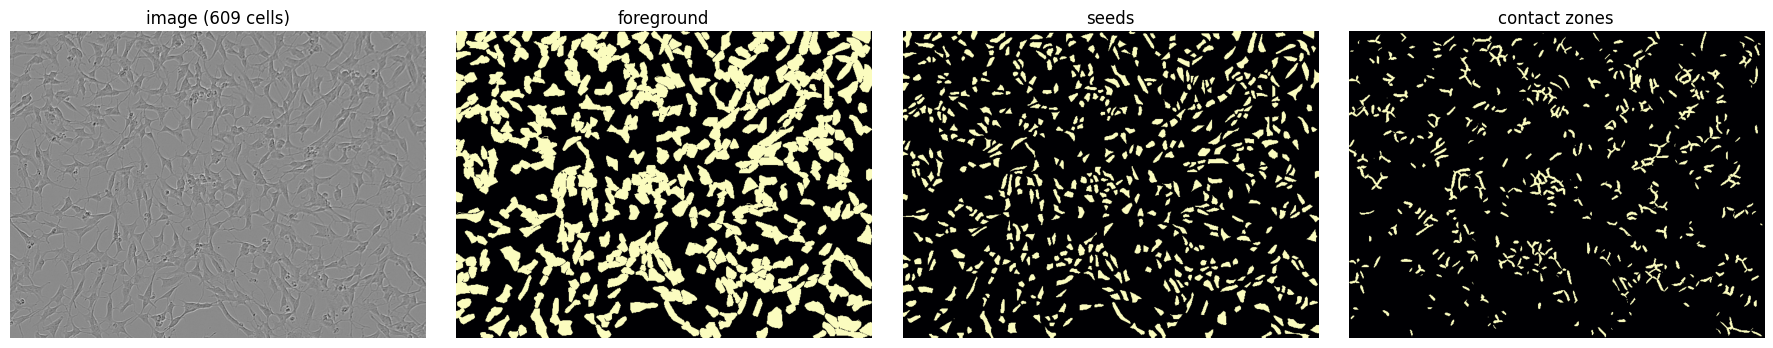

In [9]:
def build_targets(image_id):
    height, width = CFG.IMG_H, CFG.IMG_W
    foreground = np.zeros((height, width), np.uint8)
    seed = np.zeros((height, width), np.uint8)
    overlap_count = np.zeros((height, width), np.uint16)
    pad = CFG.BORDER_DILATION + 1

    for flat in INST[image_id]:
        ys, xs = np.divmod(flat.astype(np.int64), width)
        y0, y1 = max(0, ys.min() - pad), min(height, ys.max() + 1 + pad)
        x0, x1 = max(0, xs.min() - pad), min(width, xs.max() + 1 + pad)
        patch = np.zeros((y1 - y0, x1 - x0), np.uint8)
        patch[ys - y0, xs - x0] = 1

        foreground[y0:y1, x0:x1] |= patch

        distance = ndi.distance_transform_edt(patch)
        core = (distance > max(1.0, CFG.SEED_EROSION_FRAC * distance.max())).astype(np.uint8)
        seed[y0:y1, x0:x1] |= (core if core.any() else patch)

        overlap_count[y0:y1, x0:x1] += ndi.binary_dilation(
            patch, iterations=CFG.BORDER_DILATION).astype(np.uint16)

    border = (overlap_count > 1).astype(np.uint8)
    return np.stack([foreground, seed, border])

t0 = time.time()
TARGETS = {i: build_targets(i) for i in labeled_ids}
print(f"targets for {len(TARGETS)} images in {time.time() - t0:.0f}s "
      f"({sum(t.nbytes for t in TARGETS.values()) / 1e6:.0f} MB)")

demo = train_ids[int(np.argmax([len(INST[i]) for i in train_ids]))]
fig, axes = plt.subplots(1, 4, figsize=(18, 3.4))
for ax, (title, img) in zip(axes, [
        (f"image ({len(INST[demo])} cells)", IMAGES[demo]),
        ("foreground", TARGETS[demo][0]), ("seeds", TARGETS[demo][1]),
        ("contact zones", TARGETS[demo][2])]):
    ax.imshow(img, cmap="gray" if title.startswith("image") else "magma")
    ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()


## 9 · Dataset, augmentation, loaders

In [10]:
from torch.utils.data import Dataset, DataLoader

def pad_to(arr, height, width, mode="reflect"):
    ph, pw = height - arr.shape[-2], width - arr.shape[-1]
    if ph == 0 and pw == 0:
        return arr
    pad_width = [(0, 0)] * (arr.ndim - 2) + [(0, ph), (0, pw)]
    return np.pad(arr, pad_width, mode=mode)

class CellDataset(Dataset):
    def __init__(self, ids, training):
        self.ids, self.training = list(ids), bool(training)

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, index):
        image_id = self.ids[index]
        image = IMAGES[image_id].astype(np.float32) / 255.0
        target = TARGETS[image_id].copy()

        if self.training:
            image, target = self.augment(image, target)
            image, target = self.random_crop(image, target)
        else:
            image = pad_to(image, CFG.PAD_H, CFG.PAD_W)
            target = pad_to(target, CFG.PAD_H, CFG.PAD_W, mode="constant")

        tensor = torch.from_numpy(np.ascontiguousarray(image)).unsqueeze(0).repeat(3, 1, 1)
        weight = 1.0 + CFG.BORDER_WEIGHT * target[2].astype(np.float32)
        return (tensor,
                torch.from_numpy(np.ascontiguousarray(target[:2]).astype(np.float32)),
                torch.from_numpy(weight).unsqueeze(0),
                image_id)

    def augment(self, image, target):
        if random.random() < CFG.AUG_HFLIP:
            image, target = image[:, ::-1], target[:, :, ::-1]
        if random.random() < CFG.AUG_VFLIP:
            image, target = image[::-1, :], target[:, ::-1, :]
        if random.random() < CFG.AUG_ROT90:
            k = random.choice((1, 2, 3))
            image = np.rot90(image, k)
            target = np.rot90(target, k, axes=(1, 2))
        image = np.ascontiguousarray(image)
        target = np.ascontiguousarray(target)

        if random.random() < CFG.AUG_SCALE:
            scale = random.uniform(*CFG.AUG_SCALE_RANGE)
            new_size = (max(32, int(round(image.shape[1] * scale))),
                        max(32, int(round(image.shape[0] * scale))))
            image = cv2.resize(image, new_size, interpolation=cv2.INTER_LINEAR)
            target = np.stack([cv2.resize(t, new_size, interpolation=cv2.INTER_NEAREST)
                               for t in target])

        if random.random() < CFG.AUG_BRIGHTNESS_CONTRAST:
            image = np.clip((image - 0.5) * random.uniform(0.85, 1.18) + 0.5
                            + random.uniform(-0.10, 0.10), 0, 1)
        if random.random() < CFG.AUG_GAMMA:
            image = np.clip(image, 1e-4, 1.0) ** random.uniform(0.75, 1.35)
        if random.random() < CFG.AUG_NOISE:
            image = np.clip(image + np.random.normal(0, random.uniform(0.005, 0.02),
                                                     image.shape), 0, 1)
        return image.astype(np.float32), target

    def random_crop(self, image, target):
        crop_h, crop_w = CFG.CROP_H, CFG.CROP_W
        image = pad_to(image, max(crop_h, image.shape[0]), max(crop_w, image.shape[1]))
        target = pad_to(target, max(crop_h, target.shape[1]), max(crop_w, target.shape[2]),
                        mode="constant")
        top = random.randint(0, image.shape[0] - crop_h)
        left = random.randint(0, image.shape[1] - crop_w)
        return (image[top:top + crop_h, left:left + crop_w],
                target[:, top:top + crop_h, left:left + crop_w])

train_loader = DataLoader(CellDataset(train_ids, True), batch_size=CFG.BATCH_SIZE, shuffle=True,
                          num_workers=CFG.NUM_WORKERS, pin_memory=True, drop_last=True,
                          persistent_workers=CFG.NUM_WORKERS > 0)

sample_image, sample_target, sample_weight, _ = next(iter(train_loader))
print("batch:", tuple(sample_image.shape), "targets:", tuple(sample_target.shape),
      "weights:", tuple(sample_weight.shape))
print("foreground fraction:", round(float(sample_target[:, 0].mean()), 4),
      "| seed fraction:", round(float(sample_target[:, 1].mean()), 4))
print("iterations per epoch:", len(train_loader))


batch: (8, 3, 448, 576) targets: (8, 2, 448, 576) weights: (8, 1, 448, 576)
foreground fraction: 0.1146 | seed fraction: 0.0408
iterations per epoch: 42


## 10 · ConvNeXt-UNet

In [11]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True))

    def forward(self, x):
        return self.block(x)

class UNet(nn.Module):
    """ImageNet-pretrained encoder + U-Net decoder + a full-resolution stem branch.

    ConvNeXt's shallowest feature map is stride 4, which is coarse for 19-pixel cells, so a
    small stem branch computed on the raw image is concatenated before the output head.
    """

    def __init__(self, encoder_name, out_channels, decoder_channels):
        super().__init__()
        self.encoder = timm.create_model(encoder_name, pretrained=True,
                                         features_only=True, in_chans=3)
        channels = self.encoder.feature_info.channels()
        self.reductions = self.encoder.feature_info.reduction()

        blocks, in_ch = [], channels[-1]
        for i in range(len(channels) - 1):
            out_ch = decoder_channels[min(i, len(decoder_channels) - 1)]
            blocks.append(ConvBlock(in_ch + channels[-2 - i], out_ch))
            in_ch = out_ch
        self.decoder = nn.ModuleList(blocks)

        self.stem = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1, bias=False),
            nn.BatchNorm2d(16), nn.ReLU(inplace=True))
        self.head = nn.Sequential(ConvBlock(in_ch + 16, 32), nn.Conv2d(32, out_channels, 1))

    def set_encoder_trainable(self, flag):
        for parameter in self.encoder.parameters():
            parameter.requires_grad = bool(flag)

    def forward(self, x):
        features = self.encoder(x)
        y = features[-1]
        for i, block in enumerate(self.decoder):
            skip = features[-2 - i]
            y = F.interpolate(y, size=skip.shape[-2:], mode="nearest")
            y = block(torch.cat([y, skip], dim=1))
        y = F.interpolate(y, size=x.shape[-2:], mode="bilinear", align_corners=False)
        return self.head(torch.cat([y, self.stem(x)], dim=1))

encoder_name, model = None, None
for candidate in (CFG.ENCODER,) + tuple(CFG.ENCODER_FALLBACKS):
    try:
        model = UNet(candidate, CFG.OUT_CHANNELS, CFG.DECODER_CHANNELS)
        encoder_name = candidate
        break
    except Exception as error:
        print(f"encoder {candidate!r} unavailable ({type(error).__name__}); trying the next one")
assert model is not None, "No encoder could be created. Check the internet connection."
CFG.ENCODER = encoder_name
model = model.to(DEVICE)

print("encoder            :", encoder_name)
print("feature reductions :", model.reductions)
print("encoder parameters :", f"{sum(p.numel() for p in model.encoder.parameters()) / 1e6:.1f}M")
print("total parameters   :", f"{sum(p.numel() for p in model.parameters()) / 1e6:.1f}M")
with torch.no_grad():
    probe_out = model(torch.zeros(1, 3, CFG.PAD_H, CFG.PAD_W, device=DEVICE))
print("output shape       :", tuple(probe_out.shape))
assert probe_out.shape[-2:] == (CFG.PAD_H, CFG.PAD_W)
del probe_out; torch.cuda.empty_cache()
STATS["encoder"] = encoder_name


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

encoder            : convnext_tiny.fb_in22k_ft_in1k
feature reductions : [4, 8, 16, 32]
encoder parameters : 27.8M
total parameters   : 31.9M
output shape       : (1, 2, 544, 704)


## 11 · Loss, watershed decoding, validation

In [12]:
def amp_autocast():
    try:
        return torch.autocast("cuda", enabled=CFG.AMP)
    except (AttributeError, TypeError):
        return torch.cuda.amp.autocast(enabled=CFG.AMP)

def loss_fn(logits, target, weight):
    bce = F.binary_cross_entropy_with_logits(logits, target, reduction="none")
    bce = (bce * weight).mean()
    probs = torch.sigmoid(logits)
    dims = (0, 2, 3)
    intersection = (probs * target).sum(dims)
    denominator = probs.sum(dims) + target.sum(dims)
    dice = 1.0 - (2.0 * intersection + 1.0) / (denominator + 1.0)
    return bce + dice.mean()

def decode_instances(fg_prob, seed_prob, t_cell, t_seed, min_area=0):
    """Marker-controlled watershed. Returns [(score, flat_indices), ...] sorted by score."""
    foreground = fg_prob >= t_cell
    if not foreground.any():
        return []
    markers, n_markers = ndi.label(np.logical_and(seed_prob >= t_seed, foreground))
    if n_markers == 0:
        markers, n_markers = ndi.label(foreground)
        if n_markers == 0:
            return []
    labels = watershed(-fg_prob, markers=markers, mask=foreground)

    flat_labels = labels.reshape(-1)
    nonzero = np.flatnonzero(flat_labels)
    if nonzero.size == 0:
        return []
    values = flat_labels[nonzero]
    order = np.argsort(values, kind="stable")
    nonzero, values = nonzero[order], values[order]
    splits = np.flatnonzero(np.diff(values)) + 1

    flat_fg = fg_prob.reshape(-1)
    instances = []
    for group in np.split(nonzero, splits):
        if group.size < min_area:
            continue
        instances.append((float(flat_fg[group].mean()), group.astype(np.int32)))
    instances.sort(key=lambda item: -item[0])
    return instances

@torch.no_grad()
def predict_probability_maps(ids, image_dir, use_tta=None, batch_size=4, progress_every=50):
    """Returns {image_id: uint8 array [2, H, W]} — thresholds can be re-tuned without re-running."""
    use_tta = CFG.TTA_FLIPS if use_tta is None else use_tta
    model.eval()
    cache, buffer, buffer_ids = {}, [], []

    def flush():
        if not buffer:
            return
        batch = torch.stack(buffer).to(DEVICE, non_blocking=True)
        with amp_autocast():
            accumulated = torch.sigmoid(model(batch)).float()
            if use_tta:
                for dims in ([-1], [-2], [-1, -2]):
                    flipped = torch.flip(batch, dims=dims)
                    accumulated += torch.flip(torch.sigmoid(model(flipped)).float(), dims=dims)
                accumulated /= 4.0
        accumulated = accumulated[:, :, :CFG.IMG_H, :CFG.IMG_W]
        arrays = (accumulated.clamp_(0, 1) * 255).to(torch.uint8).cpu().numpy()
        for image_id, array in zip(buffer_ids, arrays):
            cache[image_id] = array
        buffer.clear(); buffer_ids.clear()

    for position, image_id in enumerate(ids, 1):
        array = (IMAGES[image_id] if image_id in IMAGES
                 else load_gray_u8(Path(image_dir) / f"{image_id}.png")).astype(np.float32) / 255.0
        array = pad_to(array, CFG.PAD_H, CFG.PAD_W)
        buffer.append(torch.from_numpy(np.ascontiguousarray(array)).unsqueeze(0).repeat(3, 1, 1))
        buffer_ids.append(image_id)
        if len(buffer) == batch_size:
            flush()
        if position % progress_every == 0:
            print(f"  predicted {position}/{len(ids)}", flush=True)
    flush()
    torch.cuda.empty_cache()
    return cache

def evaluate_maps(cache, ids, gt_by_id, t_cell, t_seed, min_area):
    predictions = {}
    for image_id in ids:
        maps = cache[image_id].astype(np.float32) / 255.0
        predictions[image_id] = [flat for _, flat in
                                 decode_instances(maps[0], maps[1], t_cell, t_seed, min_area)]
    return score_dataset_f1(gt_by_id, predictions, CFG.DICE_MATCH_THR)

print("decoding utilities ready")


decoding utilities ready


## 12 · Optimizer, EMA, schedule, checkpoint recovery

In [13]:
encoder_params = [p for p in model.encoder.parameters() if p.requires_grad]
other_params = [p for name, p in model.named_parameters()
                if p.requires_grad and not name.startswith("encoder.")]
optimizer = torch.optim.AdamW(
    [{"params": encoder_params, "lr": CFG.LR * CFG.ENCODER_LR_MULT},
     {"params": other_params, "lr": CFG.LR}],
    lr=CFG.LR, weight_decay=CFG.WEIGHT_DECAY)

steps_per_epoch = max(1, len(train_loader) // CFG.ACCUM_STEPS)
total_steps = steps_per_epoch * CFG.EPOCHS

def lr_lambda(step):
    if step < CFG.WARMUP_STEPS:
        return (step + 1) / CFG.WARMUP_STEPS
    progress = (step - CFG.WARMUP_STEPS) / max(1, total_steps - CFG.WARMUP_STEPS)
    return 0.5 * (1.0 + math.cos(math.pi * min(progress, 1.0)))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
try:
    scaler = torch.amp.GradScaler("cuda", enabled=CFG.AMP)
except (AttributeError, TypeError):
    scaler = torch.cuda.amp.GradScaler(enabled=CFG.AMP)

class EMA:
    def __init__(self, model, decay):
        self.decay = decay
        self.shadow = {k: v.detach().clone().float() if v.dtype.is_floating_point
                       else v.detach().clone() for k, v in model.state_dict().items()}

    def update(self, model):
        for key, value in model.state_dict().items():
            if value.dtype.is_floating_point:
                self.shadow[key].mul_(self.decay).add_(value.detach().float(),
                                                       alpha=1.0 - self.decay)
            else:
                self.shadow[key] = value.detach().clone()

    def state_dict(self):
        return {k: v.clone() for k, v in self.shadow.items()}

ema = EMA(model, CFG.EMA_DECAY) if CFG.USE_EMA else None

BEST_PATH, LAST_PATH = CKPT / "best.pt", CKPT / "last.pt"
start_epoch, best_score, training_log = 1, -1.0, []
FRESH_RUN = True   # set False to deliberately resume an interrupted run of THIS notebook

if not FRESH_RUN and LAST_PATH.exists():
    checkpoint = torch.load(LAST_PATH, map_location="cpu")
    model.load_state_dict(checkpoint["model"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    scheduler.load_state_dict(checkpoint["scheduler"])
    scaler.load_state_dict(checkpoint["scaler"])
    if ema is not None and checkpoint.get("ema"):
        ema.shadow = {k: v.clone() for k, v in checkpoint["ema"].items()}
    start_epoch = int(checkpoint["epoch"]) + 1
    best_score = float(checkpoint["best_score"])
    training_log = checkpoint.get("training_log", [])
    print(f"resumed from epoch {checkpoint['epoch']} with best F1={best_score:.4f}")
else:
    for stale in (BEST_PATH, LAST_PATH):
        stale.unlink(missing_ok=True)
    print("starting a fresh run")

print("steps/epoch:", steps_per_epoch, "| total steps:", total_steps,
      "| warmup:", CFG.WARMUP_STEPS)


starting a fresh run
steps/epoch: 42 | total steps: 2940 | warmup: 150


## 13 · Training

In [14]:
EVAL_MIN_AREA = int(np.percentile(areas, 1))
epoch_durations = []

for epoch in range(start_epoch, CFG.EPOCHS + 1):
    estimated = float(np.mean(epoch_durations[-3:])) if epoch_durations else 0.0
    remaining = CFG.TOTAL_BUDGET_SEC - elapsed_seconds()
    if epoch_durations and remaining < estimated + CFG.RESERVE_SEC:
        print(f"Stopping before epoch {epoch}: {format_duration(remaining)} left, "
              f"epoch costs {format_duration(estimated)}, "
              f"reserve {format_duration(CFG.RESERVE_SEC)}")
        break

    frozen = epoch <= CFG.FREEZE_ENCODER_EPOCHS
    model.set_encoder_trainable(not frozen)
    model.train()
    epoch_start, running, seen = time.time(), 0.0, 0
    optimizer.zero_grad(set_to_none=True)

    for iteration, (images, targets, weights, _) in enumerate(train_loader, 1):
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)
        weights = weights.to(DEVICE, non_blocking=True)

        with amp_autocast():
            loss = loss_fn(model(images), targets, weights)
        if not torch.isfinite(loss):
            print(f"  non-finite loss at iteration {iteration}; skipped")
            optimizer.zero_grad(set_to_none=True)
            continue

        scaler.scale(loss / CFG.ACCUM_STEPS).backward()
        running += float(loss.detach()); seen += 1

        if iteration % CFG.ACCUM_STEPS == 0 or iteration == len(train_loader):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.GRAD_CLIP)
            scaler.step(optimizer); scaler.update()
            optimizer.zero_grad(set_to_none=True); scheduler.step()
            if ema is not None:
                ema.update(model)

    duration = time.time() - epoch_start
    epoch_durations.append(duration)
    row = {"epoch": epoch, "loss": running / max(seen, 1), "frozen_encoder": frozen,
           "lr": scheduler.get_last_lr()[-1], "seconds": round(duration, 1)}

    # after the first timed epoch, shrink the schedule to what actually fits
    if len(epoch_durations) == 1 and start_epoch == 1:
        usable = CFG.TOTAL_BUDGET_SEC - elapsed_seconds() - CFG.RESERVE_SEC
        feasible = epoch + int(usable // max(duration * 1.15, 1.0))
        if feasible < CFG.EPOCHS:
            print(f">>> {duration:.0f}s/epoch -> only {feasible} epochs fit; "
                  f"rescaling the cosine schedule from {CFG.EPOCHS}")
            CFG.EPOCHS = max(epoch + 1, feasible)
            total_steps = steps_per_epoch * CFG.EPOCHS

    if epoch >= CFG.EVAL_START_EPOCH and (epoch - CFG.EVAL_START_EPOCH) % CFG.EVAL_EVERY == 0:
        val_cache = predict_probability_maps(val_ids, TRAIN_DIR, progress_every=10 ** 6)
        row["val_f1"] = evaluate_maps(val_cache, val_ids, GT_VAL,
                                      CFG.EVAL_T_CELL, CFG.EVAL_T_SEED, EVAL_MIN_AREA)
        if ema is not None:
            backup = {k: v.detach().clone() for k, v in model.state_dict().items()}
            model.load_state_dict(ema.state_dict())
            ema_cache = predict_probability_maps(val_ids, TRAIN_DIR, progress_every=10 ** 6)
            row["val_f1_ema"] = evaluate_maps(ema_cache, val_ids, GT_VAL,
                                              CFG.EVAL_T_CELL, CFG.EVAL_T_SEED, EVAL_MIN_AREA)
            model.load_state_dict(backup)
            del ema_cache, backup
        del val_cache

        use_ema = ema is not None and row.get("val_f1_ema", -1) > row["val_f1"]
        current = max(row["val_f1"], row.get("val_f1_ema", -1.0))
        if current > best_score:
            best_score = current
            torch.save({"model": ema.state_dict() if use_ema else model.state_dict(),
                        "epoch": epoch, "score": current, "used_ema": bool(use_ema),
                        "encoder": CFG.ENCODER}, BEST_PATH)
            row["saved_best"] = True
            row["best_is_ema"] = bool(use_ema)

    training_log.append(row)
    print(" | ".join(f"{k}={v:.4f}" if isinstance(v, float) else f"{k}={v}"
                     for k, v in row.items()), flush=True)

    torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(),
                "ema": ema.state_dict() if ema is not None else None, "epoch": epoch,
                "best_score": best_score, "training_log": training_log}, LAST_PATH)
    pd.DataFrame(training_log).to_csv(ART / "training_log.csv", index=False)
    gc.collect(); torch.cuda.empty_cache()

print(f"\nbest validation F1: {best_score:.4f} after {format_duration(elapsed_seconds())}")
STATS["best_val_f1"] = float(best_score)
STATS["epochs_completed"] = len(training_log)


epoch=1 | loss=1.5211 | frozen_encoder=True | lr=0.0001 | seconds=36.8000
epoch=2 | loss=1.3671 | frozen_encoder=True | lr=0.0002 | seconds=11.7000
epoch=3 | loss=1.2611 | frozen_encoder=False | lr=0.0003 | seconds=38.2000
epoch=4 | loss=1.1736 | frozen_encoder=False | lr=0.0003 | seconds=17.8000
epoch=5 | loss=1.0975 | frozen_encoder=False | lr=0.0003 | seconds=18.1000
epoch=6 | loss=1.0369 | frozen_encoder=False | lr=0.0003 | seconds=18.6000 | val_f1=0.6870 | val_f1_ema=0.0945 | saved_best=True | best_is_ema=False
epoch=7 | loss=0.9807 | frozen_encoder=False | lr=0.0003 | seconds=18.2000
epoch=8 | loss=0.9203 | frozen_encoder=False | lr=0.0003 | seconds=19.0000
epoch=9 | loss=0.8714 | frozen_encoder=False | lr=0.0003 | seconds=18.1000 | val_f1=0.7329 | val_f1_ema=0.3735 | saved_best=True | best_is_ema=False
epoch=10 | loss=0.8215 | frozen_encoder=False | lr=0.0003 | seconds=18.2000
epoch=11 | loss=0.7808 | frozen_encoder=False | lr=0.0003 | seconds=18.6000
epoch=12 | loss=0.7363 | fr

## 14 · Threshold sweep on the validation fold

In [15]:
checkpoint = torch.load(BEST_PATH, map_location="cpu")
model.load_state_dict(checkpoint["model"])
model.to(DEVICE).eval()
print("loaded best checkpoint from epoch", checkpoint["epoch"],
      "| EMA weights:", checkpoint.get("used_ema"))

VAL_MAPS = predict_probability_maps(val_ids, TRAIN_DIR, progress_every=25)

sweep_rows = []
for t_cell in CFG.SWEEP_T_CELL:
    for t_seed in CFG.SWEEP_T_SEED:
        decoded = {i: decode_instances(VAL_MAPS[i][0].astype(np.float32) / 255.0,
                                       VAL_MAPS[i][1].astype(np.float32) / 255.0,
                                       t_cell, t_seed, 0) for i in val_ids}
        for min_area in MIN_AREA_GRID:
            filtered = {i: [(s, f) for s, f in decoded[i] if f.size >= min_area] for i in val_ids}
            matrices = {i: (dice_matrix(GT_VAL[i], [f for _, f in filtered[i]]),
                            np.asarray([s for s, _ in filtered[i]], np.float32))
                        for i in val_ids}
            for score_thr in CFG.SWEEP_SCORE_THR:
                scores = []
                for image_id in val_ids:
                    dice, instance_scores = matrices[image_id]
                    keep = int((instance_scores >= score_thr).sum())
                    scores.append(instance_f1_from_dice(dice[:, :keep], CFG.DICE_MATCH_THR))
                sweep_rows.append({"t_cell": t_cell, "t_seed": t_seed, "min_area": int(min_area),
                                   "score_thr": float(score_thr), "f1": float(np.mean(scores)),
                                   "mean_predictions": float(np.mean(
                                       [int((s >= score_thr).sum()) for _, s in matrices.values()]))})
        print(f"  swept t_cell={t_cell} t_seed={t_seed} "
              f"({format_duration(elapsed_seconds())} elapsed)", flush=True)

sweep = pd.DataFrame(sweep_rows).sort_values("f1", ascending=False).reset_index(drop=True)
sweep.to_csv(ART / "sweep_results.csv", index=False)
print(sweep.head(12).to_string(index=False))

top = sweep.iloc[0]
if CFG.ROBUST_THRESHOLD:
    same_shape = sweep[np.isclose(sweep["t_cell"], top.t_cell)
                       & np.isclose(sweep["t_seed"], top.t_seed)
                       & (sweep["min_area"] == top.min_area)].sort_values("score_thr")
    plateau = same_shape[same_shape["f1"] >= top.f1 - CFG.ROBUST_TOL]
    grid = same_shape["score_thr"].to_numpy()
    chosen = float(grid[np.argmin(np.abs(grid - float(np.median(plateau["score_thr"]))))])
    print(f"plateau spans score_thr {plateau['score_thr'].min():.2f}-"
          f"{plateau['score_thr'].max():.2f}; argmax {top.score_thr:.2f} -> using {chosen:.2f}")
else:
    chosen = float(top.score_thr)

POST = {"t_cell": float(top.t_cell), "t_seed": float(top.t_seed),
        "min_area": int(top.min_area), "score_thr": chosen}
selected = sweep[np.isclose(sweep["t_cell"], POST["t_cell"])
                 & np.isclose(sweep["t_seed"], POST["t_seed"])
                 & (sweep["min_area"] == POST["min_area"])
                 & np.isclose(sweep["score_thr"], POST["score_thr"])]
VAL_F1 = float(selected["f1"].iloc[0]) if len(selected) else float(top.f1)
print("\nchosen post-processing:", POST)
print("validation F1 (honest, grouped split):", round(VAL_F1, 4))
STATS["post"] = POST
STATS["val_f1"] = VAL_F1


loaded best checkpoint from epoch 45 | EMA weights: False
  predicted 25/85
  predicted 50/85
  predicted 75/85
  swept t_cell=0.35 t_seed=0.35 (0h 46m elapsed)
  swept t_cell=0.35 t_seed=0.45 (0h 46m elapsed)
  swept t_cell=0.35 t_seed=0.55 (0h 47m elapsed)
  swept t_cell=0.35 t_seed=0.65 (0h 47m elapsed)
  swept t_cell=0.45 t_seed=0.35 (0h 48m elapsed)
  swept t_cell=0.45 t_seed=0.45 (0h 48m elapsed)
  swept t_cell=0.45 t_seed=0.55 (0h 49m elapsed)
  swept t_cell=0.45 t_seed=0.65 (0h 49m elapsed)
  swept t_cell=0.55 t_seed=0.35 (0h 50m elapsed)
  swept t_cell=0.55 t_seed=0.45 (0h 50m elapsed)
  swept t_cell=0.55 t_seed=0.55 (0h 50m elapsed)
  swept t_cell=0.55 t_seed=0.65 (0h 51m elapsed)
  swept t_cell=0.65 t_seed=0.35 (0h 51m elapsed)
  swept t_cell=0.65 t_seed=0.45 (0h 52m elapsed)
  swept t_cell=0.65 t_seed=0.55 (0h 52m elapsed)
  swept t_cell=0.65 t_seed=0.65 (0h 53m elapsed)
 t_cell  t_seed  min_area  score_thr       f1  mean_predictions
   0.55    0.65        87       0.38 0.8

## 15 · Test inference, submission, and probes

In [16]:
TEST_MAPS = predict_probability_maps(TEST_IDS, TEST_DIR, progress_every=25)
print("test inference done at", format_duration(elapsed_seconds()))

def write_submission(path, post, maps, ids):
    rows, counts, fallbacks = [], [], 0
    for image_id in ids:
        probability = maps[image_id].astype(np.float32) / 255.0
        built = decode_instances(probability[0], probability[1],
                                 post["t_cell"], post["t_seed"], post["min_area"])
        instances = [flat for score, flat in built if score >= post["score_thr"]]

        # An image with no predicted mask scores exactly 0.0, so always emit something real.
        if not instances:
            relaxed = decode_instances(probability[0], probability[1],
                                       min(0.30, post["t_cell"]), min(0.30, post["t_seed"]), 0)
            if relaxed:
                instances = [relaxed[0][1]]
                fallbacks += 1
        counts.append(len(instances))
        if not instances:
            rows.append((image_id, "-1"))
        else:
            rows.extend((image_id, flat_to_rle(flat)) for flat in instances)

    frame = pd.DataFrame(rows, columns=[ID_COL, ANN_COL])
    frame.insert(0, CFG.SUB_INDEX_COL, np.arange(len(frame), dtype=np.int64))
    frame.to_csv(path, index=False)
    assert set(frame[ID_COL].astype(str)) == set(ids), "submission is missing test images"
    assert frame[CFG.SUB_INDEX_COL].is_unique and frame[ANN_COL].notna().all()
    return {"path": str(path), "rows": len(frame), "mean_predictions": float(np.mean(counts)),
            "min": int(np.min(counts)), "max": int(np.max(counts)), "fallbacks": fallbacks}

main_info = write_submission(SUB_PATH, POST, TEST_MAPS, TEST_IDS)
print("submission:", main_info)

probe_rows = [{"file": SUB_PATH.name, "score_thr": POST["score_thr"],
               "local_val_f1": round(VAL_F1, 4),
               "mean_predictions": round(main_info["mean_predictions"], 1)}]
for delta in CFG.PROBE_DELTAS:
    probe_post = dict(POST)
    probe_post["score_thr"] = float(np.clip(round(POST["score_thr"] + delta, 2), 0.30, 0.95))
    probe_path = Path("/content") / f"submission_{CFG.RUN_TAG}_s{probe_post['score_thr']:.2f}".replace(".", "_")
    probe_path = probe_path.with_suffix(".csv")
    info = write_submission(probe_path, probe_post, TEST_MAPS, TEST_IDS)
    local = sweep[np.isclose(sweep["t_cell"], probe_post["t_cell"])
                  & np.isclose(sweep["t_seed"], probe_post["t_seed"])
                  & (sweep["min_area"] == probe_post["min_area"])
                  & np.isclose(sweep["score_thr"], probe_post["score_thr"])]
    probe_rows.append({"file": probe_path.name, "score_thr": probe_post["score_thr"],
                       "local_val_f1": round(float(local["f1"].iloc[0]), 4) if len(local) else None,
                       "mean_predictions": round(info["mean_predictions"], 1)})

PROBES = pd.DataFrame(probe_rows)
print("\n", PROBES.to_string(index=False))
print("\nGT instances/image (train): mean", round(float(counts.mean()), 1),
      "| predicted on test:", round(main_info["mean_predictions"], 1))
STATS["test_predictions"] = main_info
STATS["probes"] = probe_rows


  predicted 25/182
  predicted 50/182
  predicted 75/182
  predicted 100/182
  predicted 125/182
  predicted 150/182
  predicted 175/182
test inference done at 0h 53m
submission: {'path': '/content/submission.csv', 'rows': 18370, 'mean_predictions': 100.93406593406593, 'min': 6, 'max': 533, 'fallbacks': 0}

                                         file  score_thr  local_val_f1  mean_predictions
                              submission.csv       0.56        0.8279             100.9
submission_stage5_convnext_unet_ws_s0_46.csv       0.46        0.8279             100.9
submission_stage5_convnext_unet_ws_s0_66.csv       0.66        0.8279             100.8

GT instances/image (train): mean 125.2 | predicted on test: 100.9


## 16 · Visual check on validation images

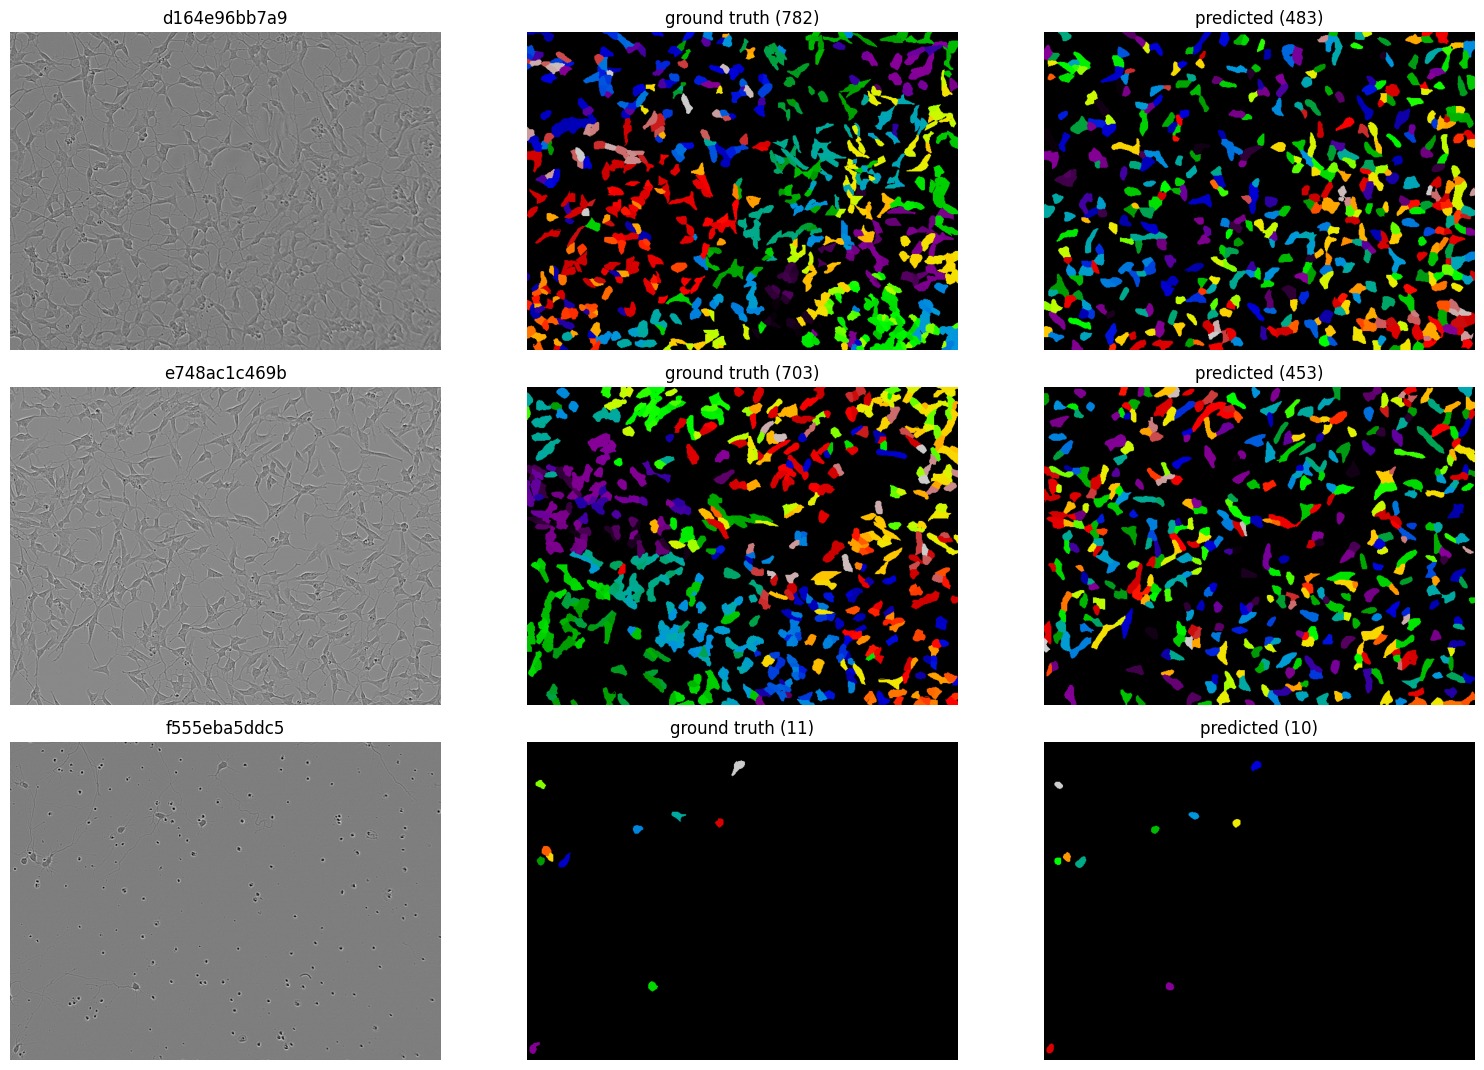

In [17]:
check_ids = sorted(val_ids, key=lambda i: -len(INST[i]))[:2] + \
             sorted(val_ids, key=lambda i: len(INST[i]))[:1]
fig, axes = plt.subplots(len(check_ids), 3, figsize=(16, 3.6 * len(check_ids)))
axes = np.atleast_2d(axes)
for row, image_id in enumerate(check_ids):
    probability = VAL_MAPS[image_id].astype(np.float32) / 255.0
    built = decode_instances(probability[0], probability[1], POST["t_cell"],
                             POST["t_seed"], POST["min_area"])
    built = [f for s, f in built if s >= POST["score_thr"]]
    painted = np.zeros(NPIX, np.int32)
    for k, flat in enumerate(built, 1):
        painted[flat] = k
    truth = np.zeros(NPIX, np.int32)
    for k, flat in enumerate(INST[image_id], 1):
        truth[flat] = k
    for ax, (title, img, cmap) in zip(axes[row], [
            (f"{image_id}", IMAGES[image_id], "gray"),
            (f"ground truth ({len(INST[image_id])})", truth.reshape(CFG.IMG_H, CFG.IMG_W), "nipy_spectral"),
            (f"predicted ({len(built)})", painted.reshape(CFG.IMG_H, CFG.IMG_W), "nipy_spectral")]):
        ax.imshow(img, cmap=cmap); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()


## 17 · Artifacts, report, download

In [18]:
if CFG.SAVE_CACHES:
    with open(ART / "test_maps.pkl", "wb") as handle:
        pickle.dump(TEST_MAPS, handle, protocol=4)
    with open(ART / "val_maps.pkl", "wb") as handle:
        pickle.dump({"maps": VAL_MAPS, "val_ids": val_ids, "post": POST,
                     "f1": VAL_F1, "run_tag": CFG.RUN_TAG}, handle, protocol=4)
    shutil.copy(BEST_PATH, ART / "selected_model.pt")
shutil.copy(SUB_PATH, ART / "submission.csv")
PROBES.to_csv(ART / "probe_submissions.csv", index=False)

report = [
    "# Stage 5 report - ConvNeXt-UNet + watershed (Colab T4)",
    f"- encoder: {CFG.ENCODER} (ImageNet only; no cell/microscopy pretraining)",
    f"- paradigm: dense prediction + marker-controlled watershed (no detection cap)",
    f"- grouped split: fold {CFG.FOLD}/{CFG.N_FOLDS} | groups {STATS.get('n_groups')} "
    f"| max val-to-train correlation {STATS.get('max_val_train_corr'):.3f}",
    f"- train/val images: {STATS.get('n_train')}/{STATS.get('n_val')}",
    f"- epochs completed: {STATS.get('epochs_completed')} of {CFG.EPOCHS}",
    f"- best checkpoint F1: {STATS.get('best_val_f1'):.4f}",
    f"- swept validation F1: {VAL_F1:.4f}",
    f"- post-processing: {POST}",
    f"- test predictions/image: mean {main_info['mean_predictions']:.1f} "
    f"(min {main_info['min']}, max {main_info['max']}, fallbacks {main_info['fallbacks']})",
    f"- total elapsed: {format_duration(elapsed_seconds())}",
    "",
    "## Probe submissions",
    PROBES.to_string(index=False),
    "",
    "Compare the honest F1 above with Stage 3's. If Stage 5 is close, it is a strong ensemble",
    "partner because its errors are structurally different. If it is far below, submit it once",
    "to see the public score and keep Stage 3 as the primary.",
]
(ART / "REPORT.md").write_text("\n".join(report))
with open(ART / "stats.json", "w") as handle:
    json.dump(STATS, handle, indent=2, default=str)

print("\n".join(report))
print("\nartifacts in", ART)
for path in sorted(ART.iterdir()):
    print(f"  {path.name:<28} {path.stat().st_size / 1e6:7.1f} MB")

try:
    from google.colab import files
    files.download(str(SUB_PATH))
    for row in probe_rows[1:]:
        files.download(str(Path("/content") / row["file"]))
except Exception as error:
    print("Automatic download unavailable:", error)
    print("Copies are in", ART)


# Stage 5 report - ConvNeXt-UNet + watershed (Colab T4)
- encoder: convnext_tiny.fb_in22k_ft_in1k (ImageNet only; no cell/microscopy pretraining)
- paradigm: dense prediction + marker-controlled watershed (no detection cap)
- grouped split: fold 0/5 | groups 424 | max val-to-train correlation 0.572
- train/val images: 339/85
- epochs completed: 70 of 70
- best checkpoint F1: 0.8157
- swept validation F1: 0.8279
- post-processing: {'t_cell': 0.55, 't_seed': 0.65, 'min_area': 87, 'score_thr': 0.56}
- test predictions/image: mean 100.9 (min 6, max 533, fallbacks 0)
- total elapsed: 0h 54m

## Probe submissions
                                        file  score_thr  local_val_f1  mean_predictions
                              submission.csv       0.56        0.8279             100.9
submission_stage5_convnext_unet_ws_s0_46.csv       0.46        0.8279             100.9
submission_stage5_convnext_unet_ws_s0_66.csv       0.66        0.8279             100.8

Compare the honest F1 above with

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>